In [3]:
#Problem Statement - A quantum circuit can produce different measurement outcomes depending 
#on the gates applied to a qubit. 

In [ ]:
 # A 2-qubit quantum circuit. 

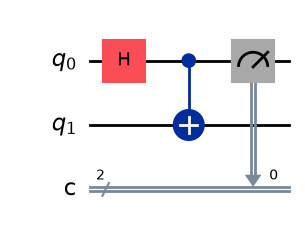

In [3]:
from qiskit import QuantumCircuit
A = QuantumCircuit(2,2)
A.h(0)
A.cx(0,1)
A.measure(0, 0)
A.draw("mpl")

In [4]:
# Modified bell circuit

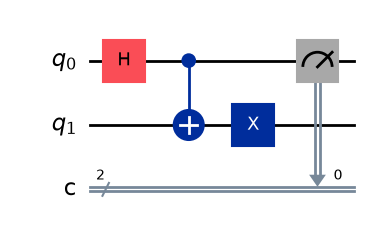

In [5]:
from qiskit import QuantumCircuit
B = QuantumCircuit(2,2)
B.h(0)
B.cx(0,1)
B.x(1)
B.measure(0, 0)
B.draw("mpl")

In [6]:
# Predict outcomes before execution
print("\nPredictions:")
print("Original: 00 and 11, approximately 50% each")
print("Modified: 01 and 10, approximately 50% each")


Predictions:
Original: 00 and 11, approximately 50% each
Modified: 01 and 10, approximately 50% each


In [7]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit import transpile

# Create a quantum simulator
simulator = AerSimulator()
shots = 100

# Execute each circuit for 100 shots
def run_circuit(qc):
    compiled_circuit = transpile(qc, simulator)
    result = simulator.run(
        compiled_circuit, shots=shots
    ).result()
    return result.get_counts()

counts_a = run_circuit(A)
counts_b = run_circuit(B)


In [8]:
print("Original circuit:", counts_a)
print("Modified circuit", counts_b)

Original circuit: {'01': 55, '00': 45}
Modified circuit {'01': 47, '00': 53}


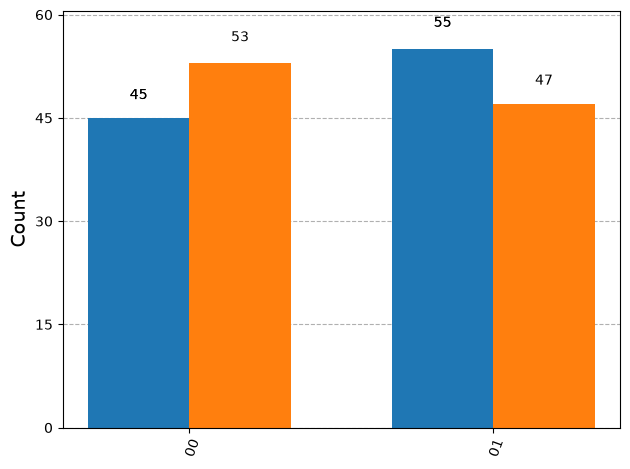

In [9]:
# Plot the histograms
from qiskit.visualization import plot_histogram
plot_histogram([counts_a, counts_b])

In [10]:
# Compare predictions with actual results
print("\nComparison:")
print("Original: Expected 00 and 11, approximately 50% each, observed counts:", counts_a)
print("Modified: Expected 10 and 10, approximately 50% each, observed counts:", counts_b)


Comparison:
Original: Expected 00 and 11, approximately 50% each, observed counts: {'01': 55, '00': 45}
Modified: Expected 10 and 10, approximately 50% each, observed counts: {'01': 47, '00': 53}
